# 🚨 Scam Message Detector — Beginner-Friendly ML Notebook

**Course:** B.Tech CSE, SGT University  |  **Project:** Scam Message Detector (AI mini project)

| Team member | Roll No. |
|---|---|
| Babita | 261302060 |
| Yashasvi | 261359010 |
| Ankita | 261302091 |

This notebook teaches a computer to read a message and say whether it is
**✅ Safe**, **⚠️ Suspicious** or **🚨 Scam**.

You do **not** need to know machine learning before reading this. Every step has a short explanation first, then a few lines of code.

---
## 📌 At a glance

| Question | Answer |
|---|---|
| **Dataset used** | **SMS Spam Collection** from the UCI Machine Learning Repository (5,574 real SMS messages, each labelled *ham* = normal or *spam* = unwanted/scam) |
| **Where is it from?** | https://archive.ics.uci.edu/dataset/228/sms+spam+collection (the notebook downloads it for you) |
| **Type of ML problem** | **Text classification** (supervised learning) |
| **How text becomes numbers** | **TF-IDF** |
| **ML models used** | **1. Naive Bayes · 2. Logistic Regression · 3. Random Forest** (many decision trees) **· 4. Combined model** that averages the first three (*soft voting*). Final system = the **average of the three models**, compared with the thresholds. |
| **How we get 3 classes** | The model gives a *scam probability* from 0 to 1. Below 0.30 → Safe, 0.30–0.70 → Suspicious, above 0.70 → Scam |
| **Libraries** | pandas, matplotlib, scikit-learn, joblib |

---
## 🗺️ Steps in this notebook

1. Import libraries
2. Load the dataset
3. Look at the data
4. Clean the text
5. Split into train / validation / test
6. Train the 3 models, combine them, and compare
7. Test the best model on unseen messages
8. Turn the scam probability into Safe / Suspicious / Scam
9. Check your own messages
10. Save the model

> **How to run:** click the first cell, then press **Shift + Enter** to run each cell one by one (or use *Kernel → Restart & Run All*).

## Step 1 — Import libraries

A *library* is ready-made code that we can reuse. If a library is missing, remove the `#` in the first line and run the cell once.

In [1]:
# !pip install pandas matplotlib scikit-learn joblib      # <- run once if something is missing

import re                       # for cleaning text
import os                       # for creating folders
import io, zipfile, urllib.request   # for downloading the dataset

import pandas as pd             # tables of data (like Excel in Python)
import matplotlib.pyplot as plt # drawing charts
import joblib                   # saving the trained model

from sklearn.model_selection import train_test_split          # splitting data
from sklearn.feature_extraction.text import TfidfVectorizer   # text -> numbers
from sklearn.pipeline import make_pipeline                    # chain steps together
from sklearn.naive_bayes import MultinomialNB                 # Model 1
from sklearn.linear_model import LogisticRegression           # Model 2
from sklearn.ensemble import RandomForestClassifier, VotingClassifier   # Model 3 + the combiner
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, ConfusionMatrixDisplay)

print("Libraries imported ✅")

Libraries imported ✅


## Step 2 — Load the dataset

**Dataset:** *SMS Spam Collection* (UCI Machine Learning Repository).
It is a text file where every line is: `label  <TAB>  message`.

* `ham`  = normal (safe) message
* `spam` = unwanted / scam message

The code below downloads the file once and saves it in a folder called `data`.

> 🔧 **If the download fails** (no internet / college network blocks it): open the link above in your browser, download the zip, extract the file named `SMSSpamCollection`, and put it inside the `data` folder next to this notebook. Then run the cell again.

In [2]:
os.makedirs("data", exist_ok=True)          # make a folder called "data"
file_path = "data/SMSSpamCollection"

# Download only if we do not already have the file
if not os.path.exists(file_path):
    url = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"
    print("Downloading dataset...")
    zip_bytes = urllib.request.urlopen(url, timeout=60).read()
    zipfile.ZipFile(io.BytesIO(zip_bytes)).extract("SMSSpamCollection", "data")

# Read the file into a table (called a DataFrame)
df = pd.read_csv(file_path, sep="\t", header=None, names=["label", "text"],
                 quoting=3, encoding="latin-1")

# Make a number column: 1 = spam/scam, 0 = ham/safe (computers like numbers)
df["is_scam"] = (df["label"] == "spam").astype(int)

print("Number of messages:", len(df))
df.head()

Number of messages: 5574


,label,text,is_scam
0,ham,"Go until jurong point, crazy.. Available only ...",0
1,ham,Ok lar... Joking wif u oni...,0
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,1
3,ham,U dun say so early hor... U c already then say...,0
4,ham,"Nah I don't think he goes to usf, he lives aro...",0


## Step 3 — Look at the data

Always look at your data first! Let us count how many safe and scam messages we have, and read a few examples.

label
ham     4827
spam     747
Name: count, dtype: int64


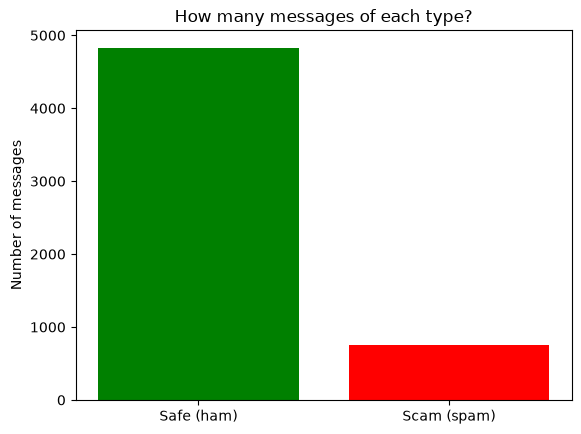


--- 3 SAFE examples ---
• Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...
• Ok lar... Joking wif u oni...
• U dun say so early hor... U c already then say...

--- 3 SCAM examples ---
• Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's
• FreeMsg Hey there darling it's been 3 week's now and no word back! I'd like some fun you up for it still? Tb ok! XxX std chgs to send, Â£1.50 to rcv
• WINNER!! As a valued network customer you have been selected to receivea Â£900 prize reward! To claim call 09061701461. Claim code KL341. Valid 12 hours only.


In [3]:
counts = df["label"].value_counts()
print(counts)

# Draw a bar chart
plt.bar(["Safe (ham)", "Scam (spam)"], [counts["ham"], counts["spam"]], color=["green", "red"])
plt.title("How many messages of each type?")
plt.ylabel("Number of messages")
plt.show()

print("\n--- 3 SAFE examples ---")
for m in df[df["label"] == "ham"]["text"].head(3):
    print("•", m)

print("\n--- 3 SCAM examples ---")
for m in df[df["label"] == "spam"]["text"].head(3):
    print("•", m)

> 💡 **Notice:** there are many more safe messages than scam messages (this is called an *imbalanced* dataset). That is why later we do not look only at *accuracy* — a model that always says "safe" would already be ~87% accurate but would miss every scam!

## Step 4 — Clean the text

Messages are messy. We make them simpler so the model can find patterns:

1. Make everything **lowercase** (`WIN` and `win` become the same word)
2. Replace **web links** with the word `urltoken` (the exact link does not matter, but *having* a link does)
3. Replace **long numbers** (phone numbers, OTPs) with `numtoken`
4. Remove symbols like `!`, `?`, `£`

In [4]:
def clean_text(text):
    text = text.lower()                                          # 1. lowercase
    text = re.sub(r"http\S+|www\.\S+", " urltoken ", text)       # 2. links
    text = re.sub(r"\d{5,}", " numtoken ", text)                 # 3. long numbers
    text = re.sub(r"[^a-z0-9 ]", " ", text)                      # 4. remove symbols
    text = re.sub(r"\s+", " ", text).strip()                     # remove extra spaces
    return text

# Try it on one message
example = "URGENT!! Your account is blocked. Click http://bit.ly/abc and send OTP 482913"
print("Before:", example)
print("After :", clean_text(example))

# Apply to the whole dataset
df["clean_text"] = df["text"].apply(clean_text)

Before: URGENT!! Your account is blocked. Click http://bit.ly/abc and send OTP 482913
After : urgent your account is blocked click urltoken and send otp numtoken


## Step 5 — Split the data: Train / Validation / Test

Imagine a student preparing for an exam:

| Part | Share | Like a student... |
|---|---|---|
| **Train** | 70% | studying from the textbook (the model learns from these) |
| **Validation** | 15% | taking a *practice test* (we use it to choose the best model) |
| **Test** | 15% | taking the *final exam* (messages the model has never seen) |

`stratify=y` makes sure each part has the same share of scam messages.
`random_state=42` makes the split the same every time you run it.

In [5]:
X = df["clean_text"]     # the input  (message text)
y = df["is_scam"]        # the answer (0 = safe, 1 = scam)

# First: 70% train, 30% for validation + test
X_train, X_rest, y_train, y_rest = train_test_split(X, y, test_size=0.30, random_state=42, stratify=y)

# Then split the 30% into half-half: 15% validation and 15% test
X_val, X_test, y_val, y_test = train_test_split(X_rest, y_rest, test_size=0.50, random_state=42, stratify=y_rest)

print("Train      :", len(X_train), "messages")
print("Validation :", len(X_val), "messages")
print("Test       :", len(X_test), "messages")

Train      : 3901 messages
Validation : 836 messages
Test       : 837 messages


## Step 6 — Train three ML models and compare them

### 6.1 Turning words into numbers: TF-IDF
Computers cannot read words, only numbers. **TF-IDF** gives each word a score:
* a word that appears **often in a message** gets a higher score,
* but a word that appears in **almost every message** (like "the") gets a low score.

So rare-but-meaningful words such as *prize*, *urgent* or *claim* stand out.

### 6.2 The three models (all are *classifiers* – they pick one label for each message)

| Model | Simple explanation |
|---|---|
| **Naive Bayes** | Counts how often each word appears in scam vs safe messages and uses probability. Very fast; a classic spam filter. |
| **Logistic Regression** | Gives every word a weight (positive = scam-like, negative = safe-like), adds them up and converts the total into a probability between 0 and 1. |
| **Random Forest** | Builds many small *decision trees* (like yes/no flowcharts) and lets them vote. |

### 6.3 Combining the three models (ensemble / voting)
Instead of trusting one model, we can ask all three and **combine their answers**, like asking three friends for advice.
We use **soft voting**: every model gives a scam probability, and we take the **average**.

| Model | Scam probability for one message |
|---|---|
| Naive Bayes | 0.94 |
| Logistic Regression | 0.86 |
| Random Forest | 0.91 |
| **Combined (average)** | **(0.94 + 0.86 + 0.91) / 3 = 0.90 → 🚨 Scam** |

Because the models make *different kinds* of mistakes, the average is often more reliable than any single one.

### 6.4 How we judge the models

* **Accuracy** – out of all messages, how many were correct?
* **Precision** – when the model says "scam", how often is it really a scam?
* **Recall** – out of all real scams, how many did the model catch? *(most important for us — we do not want to miss scams!)*
* **F1-score** – one number that balances precision and recall.

In [6]:
# A "pipeline" = TF-IDF step + model step, chained together.
# ngram_range=(1,2) means: look at single words AND pairs of words (e.g. "free entry").
# min_df=2 means: ignore words that appear in fewer than 2 messages.
models = {
    "Naive Bayes":         make_pipeline(TfidfVectorizer(ngram_range=(1, 2), min_df=2), MultinomialNB()),
    "Logistic Regression": make_pipeline(TfidfVectorizer(ngram_range=(1, 2), min_df=2),
                                         LogisticRegression(max_iter=1000, class_weight="balanced")),
    "Random Forest":       make_pipeline(TfidfVectorizer(ngram_range=(1, 2), min_df=2),
                                         RandomForestClassifier(n_estimators=100, random_state=42)),
}

# 4th model: COMBINE the three models above. voting="soft" means "average their probabilities".
models["Combined (Voting)"] = VotingClassifier(
    estimators=[("naive_bayes", models["Naive Bayes"]),
                ("logistic",    models["Logistic Regression"]),
                ("forest",      models["Random Forest"])],
    voting="soft")

results = []   # we will collect the scores here

for name, model in models.items():
    model.fit(X_train, y_train)            # TRAIN: the model learns from the training data
    pred = model.predict(X_val)            # PREDICT on the validation messages
    results.append({
        "Model": name,
        "Accuracy":  accuracy_score(y_val, pred),
        "Precision": precision_score(y_val, pred),
        "Recall":    recall_score(y_val, pred),
        "F1-score":  f1_score(y_val, pred),
    })
    print("Trained:", name)

results_table = pd.DataFrame(results).set_index("Model").round(3)
results_table

Trained: Naive Bayes


Trained: Logistic Regression


Trained: Random Forest


Trained: Combined (Voting)


,Accuracy,Precision,Recall,F1-score
Model,,,,
Naive Bayes,0.970,1.000,0.777,0.874
Logistic Regression,0.988,0.981,0.929,0.954
Random Forest,0.986,1.000,0.893,0.943
Combined (Voting),0.984,1.000,0.884,0.938


Best SINGLE model on validation data: Logistic Regression
Final model used by our system      : Combined (Voting)


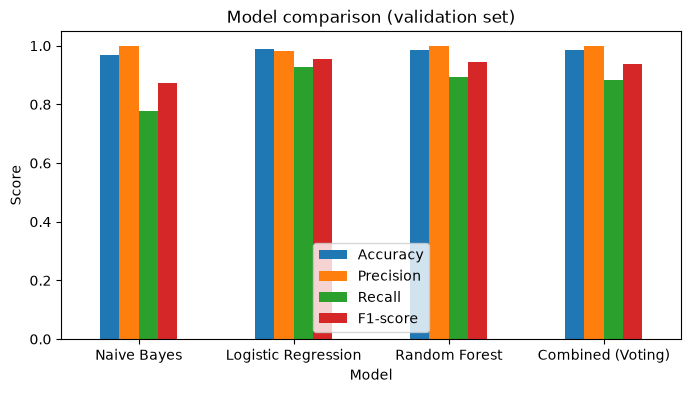

In [7]:
# Compare the models and choose the final one
best_single = results_table.drop("Combined (Voting)")["F1-score"].idxmax()
print("Best SINGLE model on validation data:", best_single)

# Our final system uses the COMBINED model: the average of Naive Bayes, Logistic Regression
# and Random Forest. (To use the single best model instead, write: best_name = best_single)
best_name = "Combined (Voting)"
best_model = models[best_name]
print("Final model used by our system      :", best_name)

results_table.plot(kind="bar", figsize=(8, 4), ylim=(0, 1.05), rot=0)
plt.title("Model comparison (validation set)")
plt.ylabel("Score")
plt.show()

## Step 7 — Final exam: test the best model on unseen messages

The **test set** has never been used so far. This tells us how well the model would do on *new* messages in real life.

The **confusion matrix** is a small table:
* top-left: safe messages correctly called safe ✅
* bottom-right: scam messages correctly caught ✅
* top-right: safe messages wrongly called scam (*false alarm*)
* bottom-left: scam messages that slipped through (*missed scam* — the most dangerous mistake)

Best model: Combined (Voting) 

              precision    recall  f1-score   support

  Safe (ham)       0.99      1.00      0.99       725
 Scam (spam)       1.00      0.90      0.95       112

    accuracy                           0.99       837
   macro avg       0.99      0.95      0.97       837
weighted avg       0.99      0.99      0.99       837



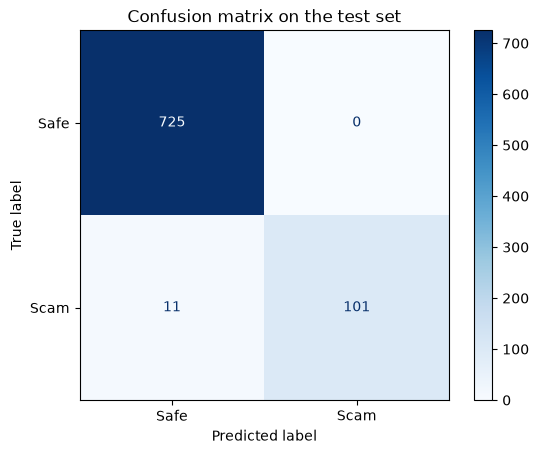

In [8]:
test_pred = best_model.predict(X_test)

print("Best model:", best_name, "\n")
print(classification_report(y_test, test_pred, target_names=["Safe (ham)", "Scam (spam)"]))

ConfusionMatrixDisplay.from_predictions(y_test, test_pred,
                                        display_labels=["Safe", "Scam"], cmap="Blues")
plt.title("Confusion matrix on the test set")
plt.show()

## Step 8 — Three answers instead of two: Safe / Suspicious / Scam

Our final system works in **two parts**:

1. **Average:** Naive Bayes, Logistic Regression and Random Forest each give a scam probability. We take the **average** of the three.
2. **Threshold:** we compare that average with two limits to get one of three answers.

The probability is a number from 0 to 1 (`predict_proba`) that tells us **how sure** the models are.

* probability **below 0.30** → ✅ Safe
* probability **between 0.30 and 0.70** → ⚠️ Suspicious (the model is unsure — be careful)
* probability **0.70 or above** → 🚨 Scam

These two limits are called **thresholds**. You can change them and see what happens!

In [9]:
SAFE_LIMIT = 0.30     # below this  -> Safe
SCAM_LIMIT = 0.70     # above this  -> Scam

def get_verdict(scam_probability):
    if scam_probability < SAFE_LIMIT:
        return "Safe"
    elif scam_probability < SCAM_LIMIT:
        return "Suspicious"
    else:
        return "Scam"

# Apply to all test messages
scam_probs = best_model.predict_proba(X_test)[:, 1]      # column 1 = probability of "scam"
verdicts = [get_verdict(p) for p in scam_probs]

# Compare the real label with what our system said
real_labels = y_test.map({0: "Really safe", 1: "Really scam"})
table = pd.crosstab(real_labels, pd.Series(verdicts, index=y_test.index, name="System said"))
table

System said,Safe,Scam,Suspicious
is_scam,,,
Really safe,725,0,0
Really scam,3,92,17


In [10]:
# How many real scams did we wrongly call "Safe"? (we want this to be as small as possible)
scam_rows = table.loc["Really scam"]
missed = scam_rows.get("Safe", 0)
print(f"Real scams called Safe (missed): {missed} out of {scam_rows.sum()}  ->  {missed / scam_rows.sum():.1%}")

safe_rows = table.loc["Really safe"]
false_alarm = safe_rows.get("Scam", 0)
print(f"Safe messages called Scam (false alarm): {false_alarm} out of {safe_rows.sum()}  ->  {false_alarm / safe_rows.sum():.1%}")

Real scams called Safe (missed): 3 out of 112  ->  2.7%
Safe messages called Scam (false alarm): 0 out of 725  ->  0.0%


### Step 8b — Watch the three models vote

The function below shows **each model's probability, the average, and the final verdict** for any message. This is exactly what happens inside the system when a new message arrives.

In [11]:
def show_how_it_works(message):
    cleaned = clean_text(message)

    # 1. Ask each of the three models for its scam probability
    p_nb = models["Naive Bayes"].predict_proba([cleaned])[0][1]
    p_lr = models["Logistic Regression"].predict_proba([cleaned])[0][1]
    p_rf = models["Random Forest"].predict_proba([cleaned])[0][1]

    # 2. Take the average of the three probabilities
    average = (p_nb + p_lr + p_rf) / 3

    # 3. Compare the average with the thresholds
    verdict = get_verdict(average)

    print("Message:", message)
    print(f"  Naive Bayes         says scam probability = {p_nb:.2f}")
    print(f"  Logistic Regression says scam probability = {p_lr:.2f}")
    print(f"  Random Forest       says scam probability = {p_rf:.2f}")
    print(f"  AVERAGE = ({p_nb:.2f} + {p_lr:.2f} + {p_rf:.2f}) / 3 = {average:.2f}")
    print(f"  Threshold check: Safe < {SAFE_LIMIT} <= Suspicious < {SCAM_LIMIT} <= Scam")
    print("  FINAL VERDICT ->", verdict.upper())
    print("-" * 70)

show_how_it_works("URGENT: Your bank account will be blocked today. Update KYC now and share the OTP sent to your phone.")
show_how_it_works("Big sale! Flat 50% off on all items this weekend only. Tap the link to see offers.")
show_how_it_works("Hi, are we still meeting at 6 pm near the library today?")

Message: URGENT: Your bank account will be blocked today. Update KYC now and share the OTP sent to your phone.
  Naive Bayes         says scam probability = 0.16
  Logistic Regression says scam probability = 0.70
  Random Forest       says scam probability = 0.21
  AVERAGE = (0.16 + 0.70 + 0.21) / 3 = 0.36
  Threshold check: Safe < 0.3 <= Suspicious < 0.7 <= Scam
  FINAL VERDICT -> SUSPICIOUS
----------------------------------------------------------------------
Message: Big sale! Flat 50% off on all items this weekend only. Tap the link to see offers.
  Naive Bayes         says scam probability = 0.07
  Logistic Regression says scam probability = 0.40
  Random Forest       says scam probability = 0.18
  AVERAGE = (0.07 + 0.40 + 0.18) / 3 = 0.22
  Threshold check: Safe < 0.3 <= Suspicious < 0.7 <= Scam
  FINAL VERDICT -> SAFE
----------------------------------------------------------------------


Message: Hi, are we still meeting at 6 pm near the library today?
  Naive Bayes         says scam probability = 0.01
  Logistic Regression says scam probability = 0.08
  Random Forest       says scam probability = 0.00
  AVERAGE = (0.01 + 0.08 + 0.00) / 3 = 0.03
  Threshold check: Safe < 0.3 <= Suspicious < 0.7 <= Scam
  FINAL VERDICT -> SAFE
----------------------------------------------------------------------


## Step 9 — Check your own messages

We also add a very simple **warning-sign finder**: a list of words that scammers like to use. It does not change the answer; it just *explains* it to the user.

In [12]:
# Simple lists of suspicious words (feel free to add your own!)
warning_words = {
    "Asks for private info": ["otp", "pin", "password", "kyc", "cvv", "verify", "aadhaar"],
    "Creates urgency":       ["urgent", "immediately", "act now", "expire", "last chance", "hurry"],
    "Offers a prize":        ["won", "winner", "prize", "lottery", "reward", "claim", "free"],
    "Threatens you":         ["blocked", "suspended", "arrest", "legal action", "police"],
    "Asks for payment":      ["pay", "fee", "transfer", "deposit"],
}

def find_warning_signs(text):
    text = text.lower()
    signs = []
    for sign_name, words in warning_words.items():
        # \b means "word boundary", so "pin" will not match inside "shopping"
        found = [w for w in words if re.search(r"\b" + w + r"\b", text)]
        if found:
            signs.append(sign_name + " -> " + ", ".join(found))
    if "http" in text or "www." in text or "bit.ly" in text:
        signs.append("Contains a link")
    return signs

def check_message(message):
    cleaned = clean_text(message)
    scam_probability = best_model.predict_proba([cleaned])[0][1]
    verdict = get_verdict(scam_probability)
    icons = {"Safe": "✅", "Suspicious": "⚠️", "Scam": "🚨"}

    print("Message :", message)
    print("Result  :", icons[verdict], verdict.upper(), f"(scam probability = {scam_probability:.2f})")
    for sign in find_warning_signs(message):
        print("   warning ->", sign)
    print("-" * 70)

# Try some example messages
check_message("Hi, are we still meeting at 6 pm near the library today?")
check_message("Big sale! Flat 50% off on all items this weekend only. Tap the link to see offers.")
check_message("URGENT: Your bank account will be blocked today. Update KYC now and share the OTP sent to your phone.")
check_message("Congratulations! You have won Rs 25,00,000 in a lucky draw. Pay Rs 5,000 processing fee to claim your prize.")

Message : Hi, are we still meeting at 6 pm near the library today?
Result  : ✅ SAFE (scam probability = 0.03)
----------------------------------------------------------------------
Message : Big sale! Flat 50% off on all items this weekend only. Tap the link to see offers.
Result  : ✅ SAFE (scam probability = 0.22)
----------------------------------------------------------------------
Message : URGENT: Your bank account will be blocked today. Update KYC now and share the OTP sent to your phone.
Result  : ⚠️ SUSPICIOUS (scam probability = 0.36)
   warning -> Asks for private info -> otp, kyc
   warning -> Creates urgency -> urgent
   warning -> Threatens you -> blocked
----------------------------------------------------------------------
Message : Congratulations! You have won Rs 25,00,000 in a lucky draw. Pay Rs 5,000 processing fee to claim your prize.
Result  : 🚨 SCAM (scam probability = 0.76)
   warning -> Offers a prize -> won, prize, claim
   warning -> Asks for payment -> pay, f

In [ ]:
# Now type your OWN message and press Enter
my_message = input("Type or paste a message to check: ")
check_message(my_message)

## Step 10 — Save the model

Training takes time, so we save the trained model to a file. Later (for example in a website made with Streamlit or Flask) we can load it and use it **without training again**.

In [13]:
joblib.dump(best_model, "scam_model.joblib")
print("Model saved as scam_model.joblib ✅")

# How to load and use it later:
loaded_model = joblib.load("scam_model.joblib")
test_text = clean_text("Your account is blocked. Share OTP now!")
print("Scam probability:", round(loaded_model.predict_proba([test_text])[0][1], 2))

Model saved as scam_model.joblib ✅


Scam probability: 0.18


---
## 📚 Mini glossary

| Word | Meaning |
|---|---|
| **Dataset** | A collection of examples the model learns from |
| **Label** | The correct answer for an example (safe or scam) |
| **Supervised learning** | Learning from examples that already have labels |
| **Classification** | Choosing a category for something (here: safe / scam) |
| **TF-IDF** | A way to turn words into numbers by scoring how important each word is |
| **Training** | The model learning patterns from the training data |
| **Threshold** | A cut-off value used to take a decision |
| **Overfitting** | When a model just memorises training data and fails on new data |

## 🧪 Try it yourself (exercises)
1. Change `SAFE_LIMIT` to 0.10 and `SCAM_LIMIT` to 0.90. Which numbers in the table change? Why?
2. Add 3 new words to `warning_words`. Do the warnings improve?
3. Change `min_df=2` to `min_df=1` in the pipelines. Does the F1-score change?
4. Write 5 messages of your own (include Hindi-English mixed ones) and see what the model says. Where does it fail?

## ⚠️ Limitations (write these in your report)
* The dataset has **only English SMS from older years**. It has few Indian-style scams (KYC, UPI, fake delivery fee, fake job offers) and no Hindi/Hinglish. Add your own labelled messages for better results.
* The dataset has only *ham* and *spam*, so the **Suspicious** zone comes from the model's uncertainty (probability thresholds), not from labelled "suspicious" examples.
* **Upgrade idea:** the *SMS Phishing Dataset* (Mishra & Soni, Mendeley Data, https://data.mendeley.com/datasets/f45bkkt8pr/1) has three labels — ham, spam and smishing — which can be used as Safe / Suspicious / Scam.

**References:** Almeida, Gómez Hidalgo & Yamakami, *Contributions to the study of SMS spam filtering*, ACM DocEng 2011 · Pedregosa et al., *Scikit-learn: Machine learning in Python*, JMLR 2011.